## Configurando bibliotecas e variáveis de ambiente

In [2]:
lazy from neuron import Neuron
lazy import os
lazy from dotenv import load_dotenv
lazy import numpy as np
lazy import random
lazy import matplotlib.pyplot as plt
lazy import json

In [3]:
load_dotenv()

True

In [4]:
DATASET_PATH = os.getenv("DATASET_PATH_3")
if DATASET_PATH and os.path.exists(DATASET_PATH):
    data = np.load(DATASET_PATH)
else:
    print("Erro: Caminho não encontrado")

In [5]:
print(data)

[[ 1.34834443e+02  9.01428613e-01  1.00000000e+00]
 [ 2.63517819e+02  1.97316968e-01  1.00000000e+00]
 [ 5.61667106e+01 -6.88010959e-01  0.00000000e+00]
 ...
 [ 2.70495031e+02  3.13910313e-01  1.00000000e+00]
 [ 3.44381264e+02 -8.62083967e-01  0.00000000e+00]
 [ 2.05396996e+01 -4.35625851e-01  0.00000000e+00]]


In [6]:
data = data.squeeze()

## Analisando o problema não-linearmente separável

### Com essa função podemos plotar um gráfico e verificar a forma que as classes estão dispostas

In [7]:
def plot_non_linear_problem(dataset):
    
    cls0 = dataset[dataset[:, 2] == 0]
    cls1 = dataset[dataset[:, 2] == 1]

    plt.scatter(cls0[:, 0], cls0[:, 1], color="red", label="Classe 0", s=20)
    plt.scatter(cls1[:, 0], cls1[:, 1], color="blue", label="Classe 1", s=20)

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.show()

### Analisando o gráfico:  
O que define um problema não-linearmente separável é quando nenhuma reta (em 2D) consegue deixar todos os pontos de uma classe de um lado e e todos os da outra classe do outro.  

Observa-se no gráfico plotado que a fronteira entre as classes possui um formato curvilíneo, quase senoidal, indicando que o problema não é linearmente separável.  

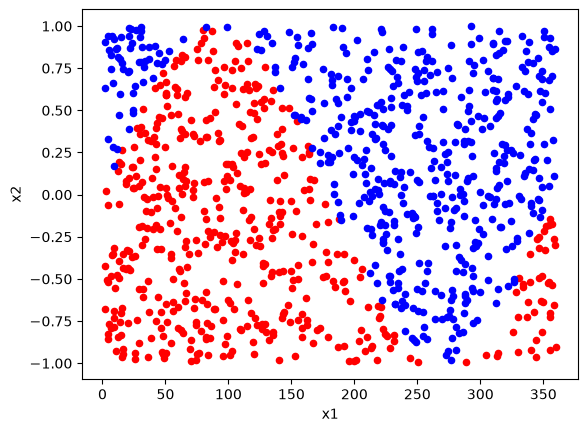

In [8]:
plot_non_linear_problem(data)

## Dividindo o dataset

In [9]:
def holdout(dataset, part_size, seed):
    config_rng = np.random.default_rng(seed)
    config_rng.shuffle(dataset)
    split = int(len(dataset)*part_size)
    train, test = dataset[:split, :], dataset[split:, :]
    return train, test

In [10]:
train, test = holdout(data, 0.7, 3)

## Construindo um novo neurônio especial (a partir do perceptron original)

### O que será que mudou?  
Senhores, temos novas funcionalidades no perceptron 2.0!  
1. É possível testar nosso neurônio com `test`  
2. Guardamos o log de treinamento e de teste  
3. Guardamos todo o log em um .json organizadinho  
4. Agora trabalhamos com métricas! Veja como seu neurônio se saiu com `confusion_matrix` e `metrics`
5. Tudo isso printado no seu terminal!

In [58]:
class NeuronSon(Neuron):
    def __init__(self, train, test, learning_rate, max_epochs):
        self.dataset = train
        self.X = np.insert(self.dataset[:, :-1], 0, 1, axis=1)
        self.Yd = self.dataset[:, -1]
        
        self.weights = np.zeros(3, dtype=float)
        self.learning_rate = learning_rate
        self.w_adjust_count = 0
        self.epochs = 0
        self.w_changes = np.empty((0, 3))

        self.test_data = test
        self.X_test = np.insert(self.test_data[:, :-1], 0, 1, axis=1)
        self.Yd_test = self.test_data[:, -1]
        
        self.max_epochs = max_epochs
        self.test_data = test

        self.trained = False
        self.tested = False

    def init_weights(self):
        self.weights[:] = np.random.uniform(-0.5, 0.5, self.weights.size)
        print(f"Vetor inicial de pesos: {self.weights}")
        
    def train(self, inputs, targets):
        n_samples = inputs.shape[0]
        self.log_train = np.zeros((self.max_epochs * n_samples, 7))
        self.w_changes = np.empty((0, self.weights.size))
        self.epochs = 0
        self.w_adjust_count = 0
        self.init_weights()
    
        print("Fazendo flexões e polichinelos....")
        row = 0
        while self.epochs < self.max_epochs:
            had_error = False
            order = np.random.permutation(n_samples)
            for i in order:
                xi = inputs[i]
                yi = targets[i]
                output = self.threshold(xi, self.weights)
                error = yi - output
    
                self.log_train[row, 0] = self.epochs + 1
                self.log_train[row, 1:4] = xi
                self.log_train[row, 4] = yi
                self.log_train[row, 5] = output
                self.log_train[row, 6] = error
                row += 1
    
                if error != 0:
                    had_error = True
                    self.w_changes = np.vstack((self.w_changes, self.weights))
                    self.weights = self.adjust_weights(xi, self.weights, error)
                    self.w_adjust_count += 1
            self.epochs += 1
            if not had_error:
                break
    
        self.log_train = self.log_train[:row]
        print("Pausa pro lanchinho...")
        self.trained = True

    def test(self):
        if not self.trained:
            raise ValueError("Somente possível testar depois de treinar")
    
        self.log_test = np.zeros((self.X_test.shape[0], 6))
        for i in range(self.X_test.shape[0]):
            xi = self.X_test[i]
            yi = self.Yd_test[i]
            output = self.threshold(xi, self.weights)
    
            self.log_test[i, 0:3] = xi
            self.log_test[i, 3] = yi
            self.log_test[i, 4] = output
            self.log_test[i, 5] = int(output == yi)
    
        hits = int(self.log_test[:, 5].sum())
        print(f"Acertos na prova: {hits}")

    def export_log(self):
        results = {
            "pesos_finais": self.weights.tolist(),
            "total_ajustes": self.w_adjust_count,
            "epocas": self.epochs,
            "treino": {
                "colunas": ["epoca", "x0", "x1", "x2", "yi", "output", "error"],
                "dados": self.log_train.tolist(),
            },
            "teste": {
                "colunas": ["x0", "x1", "x2", "yi", "output", "acertou"],
                "dados": self.log_test.tolist(),
            },
        }
        with open("results.json", "w", encoding="utf-8") as f:
            json.dump(results, f, indent=4, ensure_ascii=False)

    def confusion_matrix(self):
        if self.tested == False:
            raise ValueError("É necessário testar antes disso")
        matrix = np.zeros((2, 2), dtype=int)
        actual = self.log_test[:, 3].astype(int)
        predicted = self.log_test[:, 4].astype(int)
        np.add.at(matrix, (actual, predicted), 1)
        return matrix

    def metrics(self):
        cm = self.confusion_matrix()
        tn = cm[0, 0]
        fp = cm[0, 1]
        fn = cm[1, 0]
        tp = cm[1, 1]
    
        accuracy = (tp + tn) / (tp + tn + fp + fn)
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        if (precision + recall) > 0:
            f1score = 2 * precision * recall / (precision + recall)
        else:
            f1score = 0
    
        return accuracy, precision, recall, f1score

    def print_cm(self):
        cm = self.confusion_matrix()
        print("Matriz de confusão (teste)")
        print(f"{'':>10}{'Previsto 0':>12}{'Previsto 1':>12}")
        print(f"{'Real 0':>10}{cm[0,0]:>12}{cm[0,1]:>12}")
        print(f"{'Real 1':>10}{cm[1,0]:>12}{cm[1,1]:>12}")

    def print_metrics(self):
        accuracy, precision, recall, f1score = self.metrics()
        print(f"Acurácia: {accuracy:.2%}")
        print(f"Precisão: {precision:.2%}")
        print(f"Recall: {recall:.2%}")
        print(f"F1-score: {f1score:.2%}")

    def plot_train_test(self):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

        datasets = (
            (ax1, self.X, self.Yd, "Treino"),
            (ax2, self.X_test, self.Yd_test, "Teste"),
        )

        w0, w1, w2 = self.weights
        x = np.linspace(self.X[:, 1].min(), self.X[:, 1].max(), 2)
        y = -(w0 + w1 * x) / w2

        for ax, X, Y, title in datasets:
            class0 = X[Y == 0]
            class1 = X[Y == 1]
            ax.scatter(class0[:, 1], class0[:, 2], color="red", label="Classe 0", s=20)
            ax.scatter(class1[:, 1], class1[:, 2], color="blue", label="Classe 1", s=20)
            ax.plot(x, y, color="purple", label="Reta de decisão")

            ax.set_title(title)
            ax.set_xlabel("x1")
            ax.set_ylabel("x2")
            ax.legend()

        plt.tight_layout()
        plt.show()
        
    def executeTrain(self):
        print("Iniciando Treinamento...")
        self.train(self.X, self.Yd)
        print("Treinamento finalizado!")
        print(f"Vetor final de pesos: {self.weights}")
        print(f"Número total de ajustes no vetor de pesos: {self.w_adjust_count}")

    def executeTest(self):
        print("Iniciando teste ...")
        self.test()
        print("Teste concluído!")
        self.tested = True
        self.export_log()
        print("Acompanhe os resultados em results.json")
        

## Testando o novo neurônio com um problema não-linearmente separável

In [59]:
neuron = NeuronSon(train, test, 0.1, 100)

OBSERVAÇÃO: A taxa de aprendizado foi usada em η = 0,1, valor adotado por Haykin (2001, p. 138) no treinamento do Perceptron e que se insere no intervalo usualmente recomendado na literatura (0 < η ≤ 1). Valores muito altos de η tendem a provocar oscilações bruscas nos pesos, enquanto valores muito baixos tornam o aprendizado lento; Além disso, testes feitos com outras taxas de aprendizado mostraram valores das métricas menores que os da adotada.

In [60]:
neuron.executeTrain()

Iniciando Treinamento...
Vetor inicial de pesos: [0.25288093 0.19368749 0.38108284]
Fazendo flexões e polichinelos....
Pausa pro lanchinho...
Treinamento finalizado!
Vetor final de pesos: [-668.84711907    4.75564626  608.60103975]
Número total de ajustes no vetor de pesos: 28879


In [61]:
neuron.executeTest()

Iniciando teste ...
Acertos na prova: 234
Teste concluído!
Acompanhe os resultados em results.json


## Respondendo às perguntas

### Matriz de confusão

In [62]:
neuron.print_cm()

Matriz de confusão (teste)
            Previsto 0  Previsto 1
    Real 0          98          49
    Real 1          17         136


### Quais as métricas de desempenho da solução proposta para os dados do conjunto de treinamento inicialmente fornecido?

In [63]:
neuron.print_metrics()

Acurácia: 78.00%
Precisão: 73.51%
Recall: 88.89%
F1-score: 80.47%


### E sobre a qualidade desta solução?

Os resultados no conjunto de teste (acurácia de 78,00%, precisão de 73,51%, recall de 88,89% e F1-score de 80,47%) mostram que a solução tem qualidade moderada. O recall alto indica que o neurônio consegue identificar quase todos os exemplos da classe 1. Já a precisão mais baixa mostra que ele também erra bastante ao classificar exemplos da classe 0 como se fossem da classe 1, ou seja, gera muitos falsos positivos. Isso faz sentido pela natureza do problema: como as classes não são linearmente separáveis, nenhuma reta consegue dividi-las corretamente.

#### Observações da análise da qualidade

1. Executando o código outras vezes dá resultados diferentes de métricas.
2. Qual a classe positiva? Seria interessante saber para avaliar as métricas de um ponto de vista mais interessante.

## Gráficos

### Treinamento x Teste

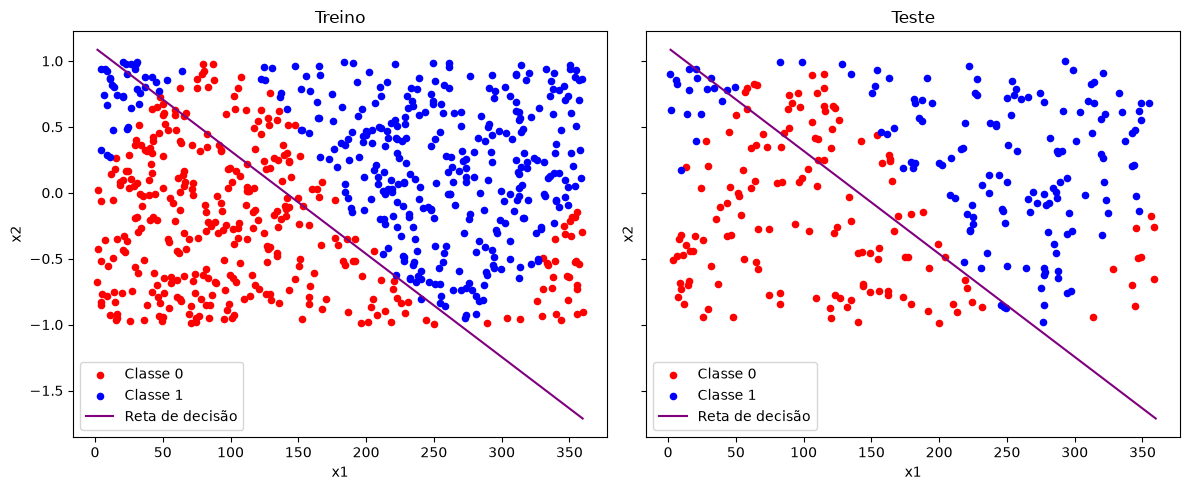

In [64]:
neuron.plot_train_test()

## Testando vários neurônios filho (NeuronSon)

Aviso: Esse teste foi feito com os objetivos de:  
1. Ver qual o melhor _learning rate_ da literatura
2. Ver a flutuação estocática dos pesos e a influência nas métricas

In [66]:
neuron1 = NeuronSon(train, test, 0.1, 100)
neuron2 = NeuronSon(train, test, 0.01, 100)
neuron3 = NeuronSon(train, test, 0.001, 100)

In [83]:
neuron1.executeTrain()

Iniciando Treinamento...
Vetor inicial de pesos: [-0.30080413  0.15488781  0.14719533]
Fazendo flexões e polichinelos....
Pausa pro lanchinho...
Treinamento finalizado!
Vetor final de pesos: [-673.30080413    5.1194427   612.47462579]
Número total de ajustes no vetor de pesos: 28980


In [84]:
neuron1.executeTest()

Iniciando teste ...
Acertos na prova: 233
Teste concluído!
Acompanhe os resultados em results.json


In [85]:
neuron1.print_metrics()

Acurácia: 77.67%
Precisão: 72.40%
Recall: 90.85%
F1-score: 80.58%


In [77]:
neuron2.executeTrain()

Iniciando Treinamento...
Vetor inicial de pesos: [-0.13185461  0.44754957  0.40001939]
Fazendo flexões e polichinelos....
Pausa pro lanchinho...
Treinamento finalizado!
Vetor final de pesos: [-67.51185461   0.84429042  61.41335021]
Número total de ajustes no vetor de pesos: 28812


In [78]:
neuron2.executeTest()

Iniciando teste ...
Acertos na prova: 199
Teste concluído!
Acompanhe os resultados em results.json


In [79]:
neuron2.print_metrics()

Acurácia: 66.33%
Precisão: 61.02%
Recall: 94.12%
F1-score: 74.04%


In [73]:
neuron3.executeTrain()

Iniciando Treinamento...
Vetor inicial de pesos: [0.11186567 0.41292323 0.41145381]
Fazendo flexões e polichinelos....
Pausa pro lanchinho...
Treinamento finalizado!
Vetor final de pesos: [-6.68313433  0.11897541  6.18996235]
Número total de ajustes no vetor de pesos: 28701


In [74]:
neuron3.executeTest()

Iniciando teste ...
Acertos na prova: 186
Teste concluído!
Acompanhe os resultados em results.json


In [76]:
neuron3.print_metrics()

Acurácia: 62.00%
Precisão: 57.77%
Recall: 94.77%
F1-score: 71.78%


Conclusões:  
- neuron1 ganhou (0.1 de taxa de aprendizado)
- Recall ta absurdo de alto :0

## Referências

HAYKIN, S. Redes neurais: princípios e prática. Tradução Paulo Martins Engel. 2. ed. Porto Alegre:
Bookman, 2001.  
FACELI, K.; LORENA, A. C.; GAMA, J.; ALMEIDA, T. A. de; CARVALHO, A. C. P. L. F. de. Inteligência
artificial: uma abordagem de aprendizado de máquina. 3. ed. rev. ampl. Rio de Janeiro: LTC, 2025.